An energy balance across a pipe wall under steady-state conditions gives

$$
\frac{d}{dr}\left(r \frac{dT}{dr}\right) =  r \frac{d^2T}{dr^2} + \frac{dT}{dr} = 0
$$

where $T$ is the temperature and $r$ is distance from the center of the pipe. The boundary condition at the inner pipe wall is given by Newton's law of cooling

$$
\dot{q}_i = -k_{PVC} \frac{dT(r_i)}{dr} = h_i [T_i^\infty - T(r_i)] 
$$

where
$k_{PVC}$ is the thermal conductivity of the PVC pipe,
$h_i$ is the convection coefficient of the fluid inside the pipe,
$T_i^\infty$ is the bulk temperature of the fluid inside the pipe,
and
$r_i$ is the inner radius of the pipe. 

Determine the temperature profile for the following conditions:

### a) 
A 6.625-inch OD (5.761-inch ID) PVC pipe. At the outer pipe wall, heat is transferred via both convection and radiation

$$
\dot{q}_o = -k_{PVC} \frac{dT(r_o)}{dr} = h_o [T(r_o) - T_o^\infty] + \epsilon \sigma [T(r_o)^4 - T_{surr}^4 ]
$$

where
$r_o$ is the outer radius of the pipe,
$T_o^\infty$ is the bulk temperature of the air,
$\epsilon$ is the emissivity of the pipe wall,
$\sigma$ is the Stefan-Boltzmann constant 5.670 $\cdot$ 10$^{-8}$ W/m$^2$/K$^4$,
and
$T_{surr}$ is the temperature of the surroundings.


### b) 
A 6.625-inch OD (5.761-inch ID) pipe with 3 inches of polyurethane (PU) insulation. At the outer pipe wall, the following conditions hold

$$ T(r_o - \delta) = T(r_o + \delta) $$

$$ \dot{q}_o = -k_{PVC} \frac{dT(r_o - \delta)}{dr} = -k_{PU} \frac{dT(r_o + \delta)}{dr} $$

where $\delta$ is an arbitrarily small parameter.

At the outer insulation wall, 
$$
\dot{q}_{ins} = -k_{PU} \frac{dT(r_{ins})}{dr} = h_o [T(r_{ins}) - T_o^\infty] + \epsilon \sigma [T(r_{ins})^4 - T_{surr}^4 ]
$$

where
$r_{ins}$ is the outer radius of the insulation. Use the following parameters:

> $h_i$ = 75.2 W/m$^2$/K  
> $h_o$ = 9.6 W/m$^2$/K  
> $k_{PVC}$ = 0.3 W/m/K  
> $k_{PU}$ = 0.04 W/m/K      
> $T_i^\infty$ = 250°C  
> $T_o^\infty$ = 25°C  
> $T_{surr}$ = 10°C  
> $\epsilon$ = 0.4



Text(0, 0.5, 'Temperature, $k$')

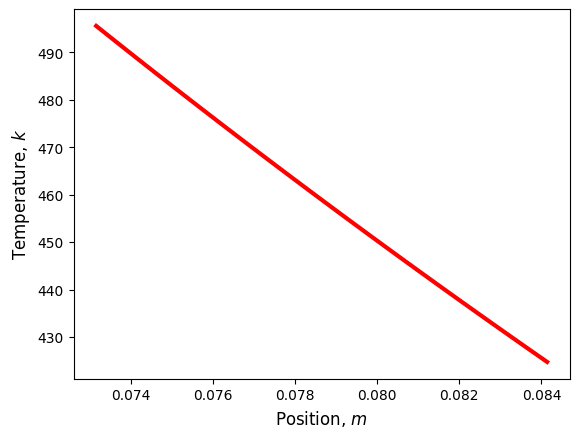

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

## internal units ##
# length: m
# temperature: K
# mass: kg
# time: seconds
# Power: Watts

# conversion
c_to_k = 273.15 
in_to_M = 0.0254

# Parameters 

hi = 75.2
ho = 9.6
Kpvc = 0.3
Kpu = 0.04
Tioo = 250+c_to_k
Tooo = 25+c_to_k
Tsurr = 10+c_to_k
epi = 0.4
boltz = 5.670e-8 


# pipe dimensions
innerD = 5.761*in_to_M
outterD = 6.625*in_to_M
r_inner = innerD/2
r_outter = outterD/2

# finite difference parameters 
N = 100 # number of points, resolution N/L 
r = np.linspace(r_inner,r_outter,N)

dr = r[1]-r[0]
dr2 = dr*dr


def ode(t,dr2): # t, temperature at every point where interested in, return all residual
    N = len(t)
    res = np.zeros(N)

    #inner pipe
    res[0] = Kpvc*(t[1]-t[0])/dr + hi*(Tioo-t[0])

    #outer pipe
    res[-1] = Kpvc*(t[-1]-t[-2])/dr + ho*(t[-1]-Tooo) + epi*boltz*(t[-1]**4-Tsurr**4)

    # interior 
    for i in range(1,N-1):
        d2t = (t[i+1]-2*t[i]+t[i-1])
        dt = (t[i+1]-t[i])
        res[i] = r[i]*d2t/dr2 + dt/dr
    return res

sol = opt.root(ode,np.ones(N),args=(dr2,))
t = sol.x

plt.plot(r,t,lw=3,color='r')
plt.xlabel('Position, $m$', fontsize = 12)
plt.ylabel('Temperature, $k$',fontsize = 12)


Text(0, 0.5, 'Temperature, $k$')

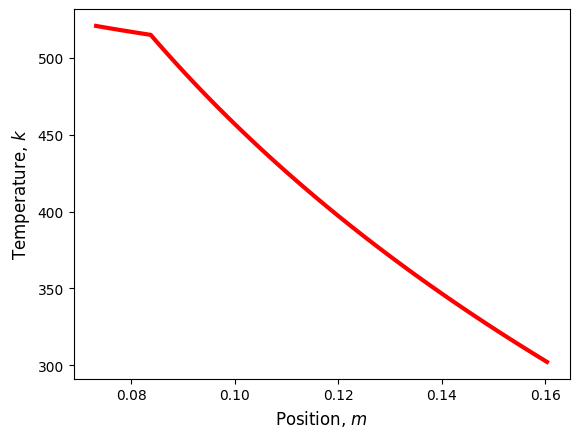

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

## internal units ##
# length: m
# temperature: K
# mass: kg
# time: seconds
# Power: Watts

# conversion
c_to_k = 273.15 
in_to_M = 0.0254

# Parameters 

hi = 75.2
ho = 9.6
Kpvc = 0.3
Kpu = 0.04
Tioo = 250+c_to_k
Tooo = 25+c_to_k
Tsurr = 10+c_to_k
epi = 0.4
boltz = 5.670e-8 


# pipe dimensions
innerD = 5.761*in_to_M
outterD = 6.625*in_to_M
r_inner = innerD/2
r_outter = outterD/2

PVC_width = 3*in_to_M

# finite difference parameters 
N = 100 # number of points, resolution N/L 
r = np.linspace(r_inner,r_outter+PVC_width,N)

dr = r[1]-r[0]
dr2 = dr*dr


def ode(t,dr2): # t, temperature at every point where interested in, return all residual
    N = len(t)
    res = np.zeros(N)

    #inner pipe
    res[0] = Kpvc*(t[1]-t[0])/dr + hi*(Tioo-t[0])

    #outer pipe, rins
    res[-1] = Kpu*(t[-1]-t[-2])/dr + ho*(t[-1]-Tooo) + epi*boltz*(t[-1]**4-Tsurr**4)

    # interior 
    for i in range(1,N-1):
        if i == np.argmin(np.abs(r - r_outter)):    # finds the index of the point closets to r_outter, were the PVC and insulation meet
            res[i] = Kpvc*(t[i]-t[i-1])/dr - Kpu*(t[i+1]-t[i])/dr   
        else:
             d2t = (t[i+1]-2*t[i]+t[i-1])
             dt = (t[i+1]-t[i])
             res[i] = r[i]*d2t/dr2 + dt/dr
    return res

sol = opt.root(ode,np.ones(N),args=(dr2,))
t = sol.x

plt.plot(r,t,lw=3,color='r')
plt.xlabel('Position, $m$', fontsize = 12)
plt.ylabel('Temperature, $k$',fontsize = 12)
